#### Notebook 04 — Population Displacement Detection

Notebook 04 builds on the completed home-location inference and residence-classification notebooks(notebook 3). The purpose of this notebook is to identify potential persistent changes in subscribers' usual nighttime locations, distinguish them from short-term movement, and quantify aggregate geographic flows.

#### Objective and assumptions

Identify potential persistent changes in subscriber nighttime locations by comparing two observation periods.

The analysis will:

1. Establish baseline nighttime locations.
2. Identify changes in dominant nighttime locations during the comparison period.
3. Measure geographic distance between baseline and comparison locations.
4. Distinguish persistent location changes from short-term or inconclusive movement.
5. Construct aggregate origin–destination flows.
6. Identify geographic destinations with elevated movement signals.

##### Important limitations

- The dataset is synthetic and does not represent actual displacement.
- A CDR/IPDR event is not continuous GPS tracking or proof of physical presence.
- A change in dominant nighttime cell is a movement signal, not confirmed displacement.
- Changes may reflect travel, work patterns, network outages, cell configuration changes, or observation gaps.
- The 14-day periods and detection thresholds are exploratory analytical choices.
- Subscriber-level results must remain private and should not be used as the sole basis for humanitarian eligibility decisions.

#### Section 2. Imports, configuration and paths

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

# PROJECT PATHS
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

NOTEBOOK02_OUTPUT = PROCESSED_PATH / "notebook_02"

NOTEBOOK03_OUTPUT = PROCESSED_PATH / "notebook_03"

NOTEBOOK04_OUTPUT = PROCESSED_PATH / "notebook_04"

REPORT_PATH = PROJECT_ROOT / "reports"

NOTEBOOK04_OUTPUT.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)

# INPUT FILES
DATA_FILE = (
    RAW_PATH / "MPD_sample_synthetic_ken_3000subs_full.csv"
)

SUBSCRIBER_CLASSIFICATION_FILE = (
    NOTEBOOK02_OUTPUT / "subscriber_classification.csv"
)

CELL_VALIDATION_FILE = (
    NOTEBOOK02_OUTPUT / "cell_coordinate_validation.csv"
)

RESIDENCE_CLASSIFICATION_FILE = (
    NOTEBOOK03_OUTPUT / "subscriber_residence_classification.csv"
)

HOME_ESTIMATES_FILE = (
    NOTEBOOK03_OUTPUT / "selected_home_location_estimates.csv"
)

# ANALYTICAL PARAMETERS
NIGHT_START_HOUR = 20
NIGHT_END_HOUR = 6

# February 1–14: baseline
# February 15–28: comparison period
PERIOD_SPLIT_DATE = pd.Timestamp("2026-02-15")

# Minimum distinct observed nights required.
MIN_BASELINE_NIGHTS = 5
MIN_FOLLOWUP_NIGHTS = 5

# Minimum nights at the dominant destination.
MIN_DESTINATION_NIGHTS = 5

# Minimum share of observed nights at dominant location.
MIN_DOMINANT_LOCATION_SHARE = 0.40

# Minimum number of weeks with destination observations.
MIN_DESTINATION_ACTIVE_WEEKS = 2

# Minimum geographic distance for a meaningful location change.
MIN_MOVEMENT_DISTANCE_KM = 5.0

# Haversine earth radius.
EARTH_RADIUS_KM = 6371.0088

# Suppress aggregate origin-destination flows below this count.
MIN_FLOW_SUBSCRIBERS = 5


print("Project root:", PROJECT_ROOT)
print("Notebook 02 outputs:", NOTEBOOK02_OUTPUT)
print("Notebook 03 outputs:", NOTEBOOK03_OUTPUT)
print("Notebook 04 outputs:", NOTEBOOK04_OUTPUT)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Notebook 02 outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_02
Notebook 03 outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_03
Notebook 04 outputs: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_04


#### Section3. Validate and load the input files

In [157]:
required_files = [
    DATA_FILE,
    SUBSCRIBER_CLASSIFICATION_FILE,
    CELL_VALIDATION_FILE,
    RESIDENCE_CLASSIFICATION_FILE,
    HOME_ESTIMATES_FILE
]

missing_files = [
    file for file in required_files
    if not file.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(str(file) for file in missing_files)
    )

print("All required input files are available.")

All required input files are available.


In [158]:
# Load raw MNO events.

df = pd.read_csv(
    DATA_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)


# Load Notebook 02 outputs.

subscriber_flags = pd.read_csv(
    SUBSCRIBER_CLASSIFICATION_FILE,
    dtype={"msisdn": "string"}
)

cell_validation = pd.read_csv(
    CELL_VALIDATION_FILE,
    dtype={"cell_id": "string"}
)

# Load Notebook 03 outputs.
residence_classification = pd.read_csv(
    RESIDENCE_CLASSIFICATION_FILE,
    dtype={"msisdn": "string"}
)

home_estimates = pd.read_csv(
    HOME_ESTIMATES_FILE,
    dtype={"msisdn": "string"}
)

# Convert data types.

df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)

df["latitude"] = pd.to_numeric(
    df["latitude"],
    errors="coerce"
)

df["longitude"] = pd.to_numeric(
    df["longitude"],
    errors="coerce"
)


print("Raw dataset:", df.shape)

print(
    "Unique subscribers:",
    df["msisdn"].nunique()
)

print(
    "Unique cells:",
    df["cell_id"].nunique()
)

print(
    "Residence classification:",
    residence_classification.shape
)

print(
    "Home estimates:",
    home_estimates.shape
)

Raw dataset: (1072608, 16)
Unique subscribers: 3000
Unique cells: 35956
Residence classification: (2813, 49)
Home estimates: (2813, 36)


In [159]:
# Validate the important columns

required_event_columns = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude"
]

required_flag_columns = [
    "msisdn",
    "subscriber_type"
]

required_cell_columns = [
    "cell_id",
    "coordinate_quality_flag"
]

required_residence_columns = [
    "msisdn",
    "residence_classification",
    "residence_evidence_level"
]

required_home_columns = [
    "msisdn",
    "selected_home_latitude",
    "selected_home_longitude",
    "has_home_estimate"
]


def validate_columns(data, required, dataset_name):

    missing = set(required) - set(data.columns)

    if missing:
        raise ValueError(
            f"{dataset_name} is missing columns: {sorted(missing)}"
        )


validate_columns(df, required_event_columns, "Raw events")

validate_columns(
    subscriber_flags,
    required_flag_columns,
    "Subscriber classification"
)

validate_columns(
    cell_validation,
    required_cell_columns,
    "Cell validation"
)

validate_columns(
    residence_classification,
    required_residence_columns,
    "Residence classification"
)

validate_columns(
    home_estimates,
    required_home_columns,
    "Home estimates"
)


assert subscriber_flags["msisdn"].is_unique
assert residence_classification["msisdn"].is_unique
assert home_estimates["msisdn"].is_unique

print("Input schema validation passed.")

Input schema validation passed.


#### Section 4. Prepare validated nighttime observations

In [160]:
# KEEP ORDINARY SUBSCRIBERS
ordinary_ids = set(
    subscriber_flags.loc[
        subscriber_flags["subscriber_type"] == "ordinary",
        "msisdn"
    ]
)

df_ordinary = df[
    df["msisdn"].isin(ordinary_ids)
].copy()


print(
    "Ordinary subscribers:",
    df_ordinary["msisdn"].nunique()
)

print(
    "Ordinary events:",
    len(df_ordinary)
)

Ordinary subscribers: 2813
Ordinary events: 968858


In [161]:
# KEEP CELLS WITH ACCEPTABLE COORDINATES
valid_cells = set(
    cell_validation.loc[
        cell_validation["coordinate_quality_flag"] == "acceptable",
        "cell_id"
    ].astype("string")
)

df_valid = df_ordinary[
    df_ordinary["cell_id"].isin(valid_cells)
].copy()


# Remove invalid timestamps and coordinates.

df_valid = df_valid.dropna(
    subset=[
        "datetime",
        "latitude",
        "longitude"
    ]
).copy()


print(
    "Events after cell validation:",
    len(df_valid)
)

print(
    "Subscribers retained:",
    df_valid["msisdn"].nunique()
)

Events after cell validation: 416243
Subscribers retained: 2813


In [162]:
# Generate the nighttime observations using the existing 20:00–06:00 definition. 
# Events after midnight are assigned to the night that began the previous evening.

df_valid["hour"] = df_valid["datetime"].dt.hour

df_valid["is_night"] = (
    (df_valid["hour"] >= NIGHT_START_HOUR)
    |
    (df_valid["hour"] < NIGHT_END_HOUR)
)

df_valid["night_id"] = (
    df_valid["datetime"]
    - pd.to_timedelta(NIGHT_END_HOUR, unit="h")
).dt.normalize()


night_events = df_valid[
    df_valid["is_night"]
].copy()


print("Nighttime events:", len(night_events))

print(
    "Subscribers with nighttime observations:",
    night_events["msisdn"].nunique()
)

print(
    "Nighttime observation period:",
    night_events["night_id"].min(),
    "to",
    night_events["night_id"].max()
)

Nighttime events: 69517
Subscribers with nighttime observations: 2758
Nighttime observation period: 2026-01-31 00:00:00 to 2026-02-28 00:00:00


#### Section 5. Establish baseline and comparison periods

In [163]:
DATA_START = night_events["night_id"].min()

DATA_END = night_events["night_id"].max()

BASELINE_START = DATA_START

BASELINE_END = PERIOD_SPLIT_DATE - pd.Timedelta(days=1)

FOLLOWUP_START = PERIOD_SPLIT_DATE

FOLLOWUP_END = DATA_END


baseline_events = night_events[
    night_events["night_id"].between(
        BASELINE_START,
        BASELINE_END
    )
].copy()


followup_events = night_events[
    night_events["night_id"].between(
        FOLLOWUP_START,
        FOLLOWUP_END
    )
].copy()


period_summary = pd.DataFrame({
    "period": [
        "Baseline",
        "Comparison"
    ],
    "start_date": [
        BASELINE_START,
        FOLLOWUP_START
    ],
    "end_date": [
        BASELINE_END,
        FOLLOWUP_END
    ],
    "events": [
        len(baseline_events),
        len(followup_events)
    ],
    "unique_subscribers": [
        baseline_events["msisdn"].nunique(),
        followup_events["msisdn"].nunique()
    ],
    "unique_nights": [
        baseline_events["night_id"].nunique(),
        followup_events["night_id"].nunique()
    ]
})


display(period_summary)

,period,start_date,end_date,events,unique_subscribers,unique_nights
0,Baseline,2026-01-31,2026-02-14,35576,2642,15
1,Comparison,2026-02-15,2026-02-28,33941,2654,14


In [164]:
# Check whether the two periods have sufficient data:

assert len(baseline_events) > 0, "Baseline period has no events."
assert len(followup_events) > 0, "Comparison period has no events."
assert BASELINE_START <= BASELINE_END
assert FOLLOWUP_START <= FOLLOWUP_END
print("Baseline and comparison periods validated.")

Baseline and comparison periods validated.


#### Section 6. Build a cell-coordinate lookup

In [165]:
# A consistent geographic reference is needed for calculating distances between locations. 
# Use median coordinates for each validated cell.

cell_lookup = (
    df_valid.groupby(
        "cell_id",
        observed=True
    )
    .agg(
        cell_latitude=("latitude", "median"),
        cell_longitude=("longitude", "median"),
        coordinate_observations=("latitude", "size")
    )
    .reset_index()
)


cell_lookup = cell_lookup.dropna(
    subset=[
        "cell_latitude",
        "cell_longitude"
    ]
)


print("Validated cells:", len(cell_lookup))

display(cell_lookup.head())

Validated cells: 24986


,cell_id,cell_latitude,cell_longitude,coordinate_observations
0,10,-1.277,36.887,1
1,100,-1.111,36.615,2
2,1000,-1.180,36.644,1
3,10003,-1.330,36.781,5
4,10004,-1.321,36.781,5


### Interpretation and Summary

The analysis successfully creates a geographic reference table (`cell_lookup`) using the median latitude and longitude of each validated cell ID.

**Key findings:**

- **Validated cells:** 24,986 unique cell IDs have usable geographic coordinates.
- **Coordinate aggregation:** Median latitude and longitude are calculated for each cell to establish a consistent geographic reference.
- **Observation counts:** `coordinate_observations` records how many coordinate observations contributed to each cell's location estimate.
- **Missing coordinates:** Cells without valid latitude or longitude values are excluded.

**Key takeaway:** The resulting `cell_lookup` provides a consolidated geographic reference for 24,986 network cells. It can be used to calculate distances between cells, identify subscriber movement patterns, perform spatial clustering, and infer residential locations.

**Important:** Cells with only one coordinate observation have less location validation than cells supported by multiple observations.

In [166]:
# Check that every cell has one coordinate record

assert cell_lookup["cell_id"].is_unique

assert cell_lookup[
    ["cell_latitude", "cell_longitude"]
].notna().all().all()

print("Cell-coordinate lookup validated.")

Cell-coordinate lookup validated.


#### Section 7. Create a Haversine distance function

In [167]:
# This calculates the approximate great-circle distance between two geographic coordinates.

def haversine_km(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        +
        np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    return EARTH_RADIUS_KM * c

In [168]:
# Quick sanity check

test_distance = haversine_km(
    -1.286389,
    36.817223,
    -1.292066,
    36.821945
)

print(
    f"Example geographic distance: {test_distance:.3f} km"
)

Example geographic distance: 0.821 km


#### Section 8. Infer dominant nighttime location in each period

The method uses one contribution per subscriber, cell and night. This reduces the influence of subscribers generating unusually high numbers of events.

For each subscriber, calculate:
- Number of observed nights.
- Number of nights at each cell.
- Dominant nighttime cell.
- Dominance share.
- Number of weeks in which the dominant cell was observed.
- Observation coverage within the period.

In [169]:
def infer_period_location(
    events,
    period_name,
    period_start,
    period_end
):

    # One contribution per subscriber, cell and night.
    subscriber_cell_night = (
        events[
            [
                "msisdn",
                "cell_id",
                "night_id"
            ]
        ]
        .drop_duplicates()
        .copy()
    )

    if subscriber_cell_night.empty:
        return pd.DataFrame()

    # Total observed nights per subscriber.
    subscriber_nights = (
        subscriber_cell_night.groupby("msisdn")
        .agg(
            observed_nights=("night_id", "nunique")
        )
        .reset_index()
    )

    # Distinct nights observed at each cell.
    cell_nights = (
        subscriber_cell_night.groupby(
            [
                "msisdn",
                "cell_id"
            ]
        )
        .agg(
            nights_at_cell=("night_id", "nunique")
        )
        .reset_index()
    )

    # Number of weeks in which each subscriber-cell
    # combination was observed.
    subscriber_cell_night["week"] = (
        subscriber_cell_night["night_id"]
        .dt.to_period("W")
        .astype(str)
    )

    cell_weeks = (
        subscriber_cell_night.groupby(
            [
                "msisdn",
                "cell_id"
            ]
        )
        .agg(
            active_weeks_at_cell=("week", "nunique")
        )
        .reset_index()
    )

    cell_nights = cell_nights.merge(
        cell_weeks,
        on=[
            "msisdn",
            "cell_id"
        ],
        how="left",
        validate="one_to_one"
    )

    # Deterministic ranking.
    cell_nights = cell_nights.sort_values(
        [
            "msisdn",
            "nights_at_cell",
            "cell_id"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )

    # Select the most frequently observed nighttime cell.
    dominant_location = (
        cell_nights
        .drop_duplicates("msisdn")
        .copy()
    )

    dominant_location = dominant_location.rename(
        columns={
            "cell_id": f"{period_name}_dominant_cell",
            "nights_at_cell": f"{period_name}_dominant_nights",
            "active_weeks_at_cell": f"{period_name}_dominant_active_weeks"
        }
    )

    # Merge total subscriber observations.
    result = dominant_location.merge(
        subscriber_nights,
        on="msisdn",
        how="left",
        validate="one_to_one"
    )

    result = result.rename(
        columns={
            "observed_nights": f"{period_name}_observed_nights"
        }
    )

    result[f"{period_name}_dominance"] = (
        result[f"{period_name}_dominant_nights"]
        / result[f"{period_name}_observed_nights"]
    )

    expected_nights = (
        pd.date_range(
            period_start,
            period_end,
            freq="D"
        ).nunique()
    )

    result[f"{period_name}_observation_coverage"] = (
        result[f"{period_name}_observed_nights"]
        / expected_nights
    )

    # Add coordinates for the dominant cell.
    result = result.merge(
        cell_lookup,
        left_on=f"{period_name}_dominant_cell",
        right_on="cell_id",
        how="left",
        validate="many_to_one"
    )

    result = result.rename(
        columns={
            "cell_latitude": f"{period_name}_latitude",
            "cell_longitude": f"{period_name}_longitude"
        }
    )

    result = result.drop(
        columns=[
            "cell_id",
            "coordinate_observations"
        ],
        errors="ignore"
    )

    return result

In [170]:
# Run the inference independently for the two periods

baseline_location = infer_period_location(
    baseline_events,
    period_name="baseline",
    period_start=BASELINE_START,
    period_end=BASELINE_END
)


followup_location = infer_period_location(
    followup_events,
    period_name="followup",
    period_start=FOLLOWUP_START,
    period_end=FOLLOWUP_END
)


print(
    "Subscribers with baseline location:",
    baseline_location["msisdn"].nunique()
)

print(
    "Subscribers with comparison location:",
    followup_location["msisdn"].nunique()
)


display(baseline_location.head())

display(followup_location.head())

Subscribers with baseline location: 2642
Subscribers with comparison location: 2654


,msisdn,baseline_dominant_cell,baseline_dominant_nights,baseline_dominant_active_weeks,baseline_observed_nights,baseline_dominance,baseline_observation_coverage,baseline_latitude,baseline_longitude
0,subscribers_00000,10235,1,1,2,0.500,0.133,-1.256,36.784
1,subscribers_00001,23709,1,1,2,0.500,0.133,-1.310,36.868
2,subscribers_00002,28284,3,2,6,0.500,0.400,-1.220,36.887
3,subscribers_00003,18804,11,2,14,0.786,0.933,-1.274,36.837
4,subscribers_00004,20162,1,1,1,1.000,0.067,-1.364,36.845


,msisdn,followup_dominant_cell,followup_dominant_nights,followup_dominant_active_weeks,followup_observed_nights,followup_dominance,followup_observation_coverage,followup_latitude,followup_longitude
0,subscribers_00000,10235,1,1,1,1.000,0.071,-1.256,36.784
1,subscribers_00001,22964,1,1,4,0.250,0.286,-1.307,36.862
2,subscribers_00002,22951,7,2,10,0.700,0.714,-1.319,36.862
3,subscribers_00003,18804,11,3,12,0.917,0.857,-1.274,36.837
4,subscribers_00004,4950,1,1,3,0.333,0.214,-1.303,36.713


### Interpretation and Summary

The analysis independently infers each subscriber's dominant nighttime location during the baseline and follow-up periods. The dominant location is the cell where the subscriber was observed on the highest number of distinct nights.

**Key findings:**

- **Baseline coverage:** 2,642 subscribers have an identifiable dominant nighttime location.
- **Follow-up coverage:** 2,654 subscribers have an identifiable dominant nighttime location, representing 12 more subscribers than the baseline.
- **Dominant location:** Each subscriber is assigned the cell with the highest number of distinct nighttime observations.
- **Location dominance:** Measures how frequently the subscriber appears at their dominant cell relative to their total observed nights. Higher values indicate stronger location concentration.
- **Observation coverage:** Measures the proportion of expected nights for which subscriber activity was observed during each period.
- **Geographic coordinates:** Median cell latitude and longitude are attached to each dominant location to enable spatial comparisons.

**Important observations:**

- Subscriber `00003` demonstrates relatively consistent location behaviour, with cell `18804` dominating both periods (11 nights in each).
- Subscriber `00000` also retains cell `10235` as their dominant location across both periods, although observation coverage is limited.
- Other subscribers show changes in their dominant cell IDs, potentially indicating residential relocation, changes in nighttime mobility, or differences in observation coverage.

**Key takeaway:** The analysis establishes a comparable nighttime location baseline for 2,642 subscribers and a follow-up location for 2,654 subscribers. These results provide the foundation for measuring geographic stability, identifying potential residential relocation, and detecting changes in subscriber mobility between the two periods.

**Important:** A change in dominant cell does not automatically indicate residential relocation. Location dominance and observation coverage should both be considered when interpreting geographic changes.

#### Section 9. Compare baseline and comparison locations

In [171]:
movement_analysis = baseline_location.merge(
    followup_location,
    on="msisdn",
    how="outer",
    validate="one_to_one"
)


print(
    "Subscribers in combined movement analysis:",
    movement_analysis["msisdn"].nunique()
)


display(movement_analysis.head())

Subscribers in combined movement analysis: 2758


,msisdn,baseline_dominant_cell,baseline_dominant_nights,baseline_dominant_active_weeks,baseline_observed_nights,baseline_dominance,baseline_observation_coverage,baseline_latitude,baseline_longitude,followup_dominant_cell,followup_dominant_nights,followup_dominant_active_weeks,followup_observed_nights,followup_dominance,followup_observation_coverage,followup_latitude,followup_longitude
0,subscribers_00000,10235,1.000,1.000,2.000,0.500,0.133,-1.256,36.784,10235,1.000,1.000,1.000,1.000,0.071,-1.256,36.784
1,subscribers_00001,23709,1.000,1.000,2.000,0.500,0.133,-1.310,36.868,22964,1.000,1.000,4.000,0.250,0.286,-1.307,36.862
2,subscribers_00002,28284,3.000,2.000,6.000,0.500,0.400,-1.220,36.887,22951,7.000,2.000,10.000,0.700,0.714,-1.319,36.862
3,subscribers_00003,18804,11.000,2.000,14.000,0.786,0.933,-1.274,36.837,18804,11.000,3.000,12.000,0.917,0.857,-1.274,36.837
4,subscribers_00004,20162,1.000,1.000,1.000,1.000,0.067,-1.364,36.845,4950,1.000,1.000,3.000,0.333,0.214,-1.303,36.713


In [172]:
# Calculate the distance between each subscriber's dominant nighttime locations

movement_analysis["baseline_to_followup_distance_km"] = (
    haversine_km(
        movement_analysis["baseline_latitude"],
        movement_analysis["baseline_longitude"],
        movement_analysis["followup_latitude"],
        movement_analysis["followup_longitude"]
    )
)


display(
    movement_analysis[
        [
            "msisdn",
            "baseline_dominant_cell",
            "followup_dominant_cell",
            "baseline_observed_nights",
            "followup_observed_nights",
            "baseline_dominance",
            "followup_dominance",
            "baseline_to_followup_distance_km"
        ]
    ].head(20)
)

,msisdn,baseline_dominant_cell,followup_dominant_cell,baseline_observed_nights,followup_observed_nights,baseline_dominance,followup_dominance,baseline_to_followup_distance_km
0,subscribers_00000,10235,10235,2.000,1.000,0.500,1.000,0.000
1,subscribers_00001,23709,22964,2.000,4.000,0.500,0.250,0.672
2,subscribers_00002,28284,22951,6.000,10.000,0.500,0.700,11.429
3,subscribers_00003,18804,18804,14.000,12.000,0.786,0.917,0.000
4,subscribers_00004,20162,4950,1.000,3.000,1.000,0.333,16.130
5,subscribers_00005,13984,15009,5.000,7.000,0.200,0.143,3.807
6,subscribers_00006,41360,7751,1.000,1.000,1.000,1.000,2.355
7,subscribers_00007,28155,28155,14.000,12.000,1.000,0.917,0.000
8,subscribers_00008,2047,2047,8.000,7.000,0.750,0.857,0.000
9,subscribers_00009,<NA>,19687,NaN,2.000,NaN,1.000,NaN


### Interpretation and Summary

The analysis measures the geographic distance between each subscriber's dominant nighttime location during the baseline and follow-up periods to identify potential residential movement or changes in nighttime mobility.

**Key findings:**

- **Location stability:** Several subscribers retain the same dominant cell across both periods, suggesting geographic stability.
- **No geographic movement:** Subscribers such as `00000`, `00003`, `00007`, `00008`, `00010`, `00012` and `00017` have a distance of 0 km between their dominant locations.
- **Potential relocation or movement:** Some subscribers show substantial geographic changes:
  - Subscriber `00002`: 11.43 km.
  - Subscriber `00004`: 16.13 km.
  - Subscriber `00015`: 13.17 km.
  - Subscriber `00019`: 7.41 km.
- **Changes in dominance:** Some subscribers retain the same dominant cell but exhibit changes in dominance, indicating changes in how concentrated their nighttime activity is.
- **Missing locations:** Subscribers `00009` and `00011` lack comparable locations across both periods, preventing distance calculations.

**Key takeaway:** The distance metric provides an initial indication of geographic stability and potential residential movement. Subscribers with larger baseline-to-follow-up distances warrant further investigation to determine whether they experienced residential relocation or changes in nighttime mobility.

**Important:** A change in dominant nighttime cell does not necessarily indicate a change of residence. Observation coverage, location dominance and residential consistency should be considered before classifying a subscriber as having relocated.

#### Section 10. Add residence classification context

Notebook 03 provides useful supporting evidence about subscribers' previously inferred residence patterns. Attach this information for interpretation, but do not use the full-month home estimate as the baseline location. That avoids allowing later observations to determine the baseline against which they are compared.

In [173]:
residence_context = residence_classification[
    [
        "msisdn",
        "residence_classification",
        "residence_evidence_level"
    ]
].copy()


movement_analysis = movement_analysis.merge(
    residence_context,
    on="msisdn",
    how="left",
    validate="one_to_one"
)


display(
    movement_analysis[
        [
            "msisdn",
            "residence_classification",
            "residence_evidence_level",
            "baseline_dominant_cell",
            "followup_dominant_cell",
            "baseline_to_followup_distance_km"
        ]
    ].head(20)
)

,msisdn,residence_classification,residence_evidence_level,baseline_dominant_cell,followup_dominant_cell,baseline_to_followup_distance_km
0,subscribers_00000,uncertain_weak_home_presence,insufficient,10235,10235,0.000
1,subscribers_00001,recurring_presence_not_yet_stable,moderate,23709,22964,0.672
2,subscribers_00002,recurring_presence_not_yet_stable,moderate,28284,22951,11.429
3,subscribers_00003,likely_stable_resident,strong,18804,18804,0.000
4,subscribers_00004,uncertain_weak_home_presence,insufficient,20162,4950,16.130
5,subscribers_00005,recurring_presence_not_yet_stable,moderate,13984,15009,3.807
6,subscribers_00006,uncertain_insufficient_home_estimate,insufficient,41360,7751,2.355
7,subscribers_00007,likely_stable_resident,strong,28155,28155,0.000
8,subscribers_00008,likely_stable_resident,moderate,2047,2047,0.000
9,subscribers_00009,uncertain_insufficient_home_estimate,insufficient,<NA>,19687,NaN


### Interpretation and Summary

This analysis combines each subscriber's inferred residential classification and evidence strength with their baseline and follow-up dominant nighttime locations.

**Key findings:**

- **Residential context:** Each subscriber is now associated with a residential classification (`likely_stable_resident`, `recurring_presence_not_yet_stable`, or an uncertain category) and an evidence level (`strong`, `moderate`, or `insufficient`).
- **Geographic stability:** Several subscribers classified as likely stable residents, including `00003`, `00007`, `00010`, `00012` and `00017`, retained the same dominant nighttime cell across both periods (0 km movement).
- **Potential relocation:** Some subscribers show substantial changes in dominant nighttime location:
  - Subscriber `00002`: 11.43 km.
  - Subscriber `00004`: 16.13 km.
  - Subscriber `00015`: 13.17 km.
  - Subscriber `00019`: 7.41 km.
- **Evidence quality:** Subscribers with insufficient residential evidence should be treated cautiously, even when their dominant nighttime locations change.
- **Missing observations:** Subscribers `00009` and `00011` lack comparable locations across both periods, so their movement cannot be determined.

**Key takeaway:**

Combining residential classification with geographic movement provides a stronger basis for identifying potential residential changes than distance alone. Subscribers with substantial geographic displacement and strong residential evidence are the most useful candidates for further relocation investigation.

**Important:** A change in dominant nighttime location is an indicator of potential movement, not definitive proof of residential relocation. Observation coverage and consistency across both periods should also be considered.

#### Section 11. Classify potential movement and displacement signals

Use conservative rules:
- At least five observed nights in each period.
- At least five nights at the comparison-period dominant location.
- At least 40% of observed comparison-period nights at that location.
- Observations in at least two separate weeks.
- A geographic shift of at least 5 km.
- Baseline evidence of a recurring dominant location.

These are initial analytical thresholds, not calibrated displacement criteria. Notebook 05 will test their sensitivity.

In [174]:
# Baseline stability is assessed using baseline observations only.
movement_analysis["baseline_stability_supported"] = (
    (
        movement_analysis["baseline_observed_nights"]
        >= MIN_BASELINE_NIGHTS
    )
    &
    (
        movement_analysis["baseline_dominance"]
        >= 0.50
    )
)


# Is there enough evidence in both periods?
movement_analysis["sufficient_period_evidence"] = (
    (
        movement_analysis["baseline_observed_nights"]
        >= MIN_BASELINE_NIGHTS
    )
    &
    (
        movement_analysis["followup_observed_nights"]
        >= MIN_FOLLOWUP_NIGHTS
    )
)


# Is the new dominant location persistent?
movement_analysis["persistent_new_location"] = (
    (
        movement_analysis["followup_dominant_nights"]
        >= MIN_DESTINATION_NIGHTS
    )
    &
    (
        movement_analysis["followup_dominance"]
        >= MIN_DOMINANT_LOCATION_SHARE
    )
    &
    (
        movement_analysis["followup_dominant_active_weeks"]
        >= MIN_DESTINATION_ACTIVE_WEEKS
    )
)


# Is the geographic change meaningful?
movement_analysis["meaningful_geographic_shift"] = (
    movement_analysis["baseline_to_followup_distance_km"]
    >= MIN_MOVEMENT_DISTANCE_KM
)

In [175]:
# Assign a movement classification

def classify_movement_signal(row):

    if pd.isna(row["baseline_observed_nights"]):
        return "insufficient_baseline_observations"

    if pd.isna(row["followup_observed_nights"]):
        return "insufficient_followup_observations"

    if row["baseline_observed_nights"] < MIN_BASELINE_NIGHTS:
        return "insufficient_baseline_observations"

    if row["followup_observed_nights"] < MIN_FOLLOWUP_NIGHTS:
        return "insufficient_followup_observations"

    if pd.isna(row["baseline_to_followup_distance_km"]):
        return "insufficient_geographic_information"

    if (
        not row["meaningful_geographic_shift"]
    ):
        return "no_material_location_change"

    if (
        row["persistent_new_location"]
        and row["baseline_stability_supported"]
    ):
        return "potential_persistent_displacement_signal"

    if row["persistent_new_location"]:
        return "persistent_location_change_unstable_baseline"

    return "possible_short_term_or_uncertain_movement"


movement_analysis["movement_signal"] = (
    movement_analysis.apply(
        classify_movement_signal,
        axis=1
    )
)


# This is a candidate flag, not confirmation of displacement.
movement_analysis["potential_displacement_candidate"] = (
    movement_analysis["movement_signal"]
    == "potential_persistent_displacement_signal"
)


display(
    movement_analysis[
        [
            "msisdn",
            "baseline_observed_nights",
            "followup_observed_nights",
            "baseline_dominance",
            "followup_dominance",
            "baseline_to_followup_distance_km",
            "baseline_stability_supported",
            "persistent_new_location",
            "movement_signal",
            "potential_displacement_candidate"
        ]
    ].head(25)
)

,msisdn,baseline_observed_nights,followup_observed_nights,baseline_dominance,followup_dominance,baseline_to_followup_distance_km,baseline_stability_supported,persistent_new_location,movement_signal,potential_displacement_candidate
0,subscribers_00000,2.000,1.000,0.500,1.000,0.000,False,False,insufficient_baseline_observations,False
1,subscribers_00001,2.000,4.000,0.500,0.250,0.672,False,False,insufficient_baseline_observations,False
2,subscribers_00002,6.000,10.000,0.500,0.700,11.429,True,True,potential_persistent_displacement_signal,True
3,subscribers_00003,14.000,12.000,0.786,0.917,0.000,True,True,no_material_location_change,False
4,subscribers_00004,1.000,3.000,1.000,0.333,16.130,False,False,insufficient_baseline_observations,False
5,subscribers_00005,5.000,7.000,0.200,0.143,3.807,False,False,no_material_location_change,False
6,subscribers_00006,1.000,1.000,1.000,1.000,2.355,False,False,insufficient_baseline_observations,False
7,subscribers_00007,14.000,12.000,1.000,0.917,0.000,True,True,no_material_location_change,False
8,subscribers_00008,8.000,7.000,0.750,0.857,0.000,True,True,no_material_location_change,False
9,subscribers_00009,NaN,2.000,NaN,1.000,NaN,False,False,insufficient_baseline_observations,False


### Interpretation and Summary

The analysis evaluates whether subscribers experienced meaningful and potentially persistent changes in their dominant nighttime locations between the baseline and follow-up periods.

**Key findings (2,758 subscribers):**

| Movement classification | Subscribers | Percentage |
|---|---:|---:|
| Insufficient baseline observations | 1,236 | 44.8% |
| No material location change | 983 | 35.6% |
| Insufficient follow-up observations | 407 | 14.8% |
| Possible short-term or uncertain movement | 131 | 4.7% |
| Potential persistent displacement | 1 | 0.04% |

**Key observations:**

- **Geographic stability:** 983 subscribers (35.6%) retained approximately the same dominant nighttime location across both periods.
- **Potential movement:** 131 subscribers (4.7%) experienced meaningful geographic changes, but the evidence was insufficient to establish persistent displacement.
- **Insufficient evidence:** 1,643 subscribers (59.6%) lacked sufficient baseline or follow-up observations for reliable movement classification.
- **Persistent displacement:** Only one subscriber satisfied all displacement criteria.

**Notable candidate:**

Subscriber `subscribers_00002`:
- Baseline dominant location: 6 observed nights.
- Follow-up dominant location: 10 observed nights.
- Geographic displacement: 11.43 km.
- Baseline dominance: 50%.
- Follow-up dominance: 70%.
- Follow-up location persistence: Meets the defined criteria.

This subscriber demonstrates a potential persistent displacement signal, although their residential classification is only `recurring_presence_not_yet_stable` with moderate evidence.

**Key takeaway:**

The analysis identifies substantial geographic stability among subscribers with sufficient observations. However, limited observation coverage prevents reliable movement classification for many subscribers.

The single displacement candidate should be prioritised for further investigation rather than treated as a confirmed residential relocation.

**Important limitation:** Movement between dominant nighttime cells does not necessarily establish a change of residence. Longer observation periods and stronger residential evidence would improve confidence in displacement detection.

In [176]:
# Export Report
movement_analysis.to_csv(
    NOTEBOOK04_OUTPUT / "movement_analysis_classification.csv",
    index=False
)

In [177]:
# Summarise the movement classifications

movement_summary = (
    movement_analysis["movement_signal"]
    .value_counts()
    .rename_axis("movement_signal")
    .reset_index(name="subscriber_count")
)

movement_summary["percentage"] = (
    movement_summary["subscriber_count"]
    / movement_summary["subscriber_count"].sum()
    * 100
)


display(movement_summary)

,movement_signal,subscriber_count,percentage
0,insufficient_baseline_observations,1236,44.815
1,no_material_location_change,983,35.642
2,insufficient_followup_observations,407,14.757
3,possible_short_term_or_uncertain_movement,131,4.750
4,potential_persistent_displacement_signal,1,0.036


#### Section 12. Measure movement distances

In [178]:
distance_summary = (
    movement_analysis[
        "baseline_to_followup_distance_km"
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
    .to_frame("distance_km")
)


display(distance_summary)

,distance_km
count,"2,538.000"
mean,3.537
std,5.763
min,0.000
25%,0.000
50%,0.708
75%,5.067
90%,10.554
95%,15.345
max,52.074


### Interpretation and Summary

The distance distribution measures how far subscribers' dominant nighttime locations shifted between the baseline and follow-up periods.

**Key observations:**

- **Number of subscribers:** 2,538 had valid geographic distance measurements.
- **Mean distance:** 3.54 km, indicating relatively small average geographic movement.
- **Median distance:** 0.71 km, suggesting that at least half of subscribers experienced shifts of less than 1 km.
- **75th percentile:** 5.07 km, meaning 75% of subscribers experienced shifts of approximately 5 km or less.
- **90th percentile:** 10.55 km, indicating that most subscribers remained within relatively short geographic distances.
- **95th percentile:** 15.35 km, suggesting that larger movements were concentrated among a smaller proportion of subscribers.
- **Maximum distance:** 52.07 km, representing the largest observed shift.

**Key takeaway:**

Most subscribers demonstrate relatively stable nighttime geographic patterns, with a median shift of just 0.71 km. However, a smaller group experienced substantial geographic changes, with approximately 10% shifting more than 10.55 km.

The difference between the mean (3.54 km) and median (0.71 km) indicates a right-skewed distribution, suggesting that a relatively small number of large movements influence the average.

**Conclusion:** Geographic movement is generally limited across the subscriber population, although a small subset exhibits potentially significant location changes requiring further investigation.

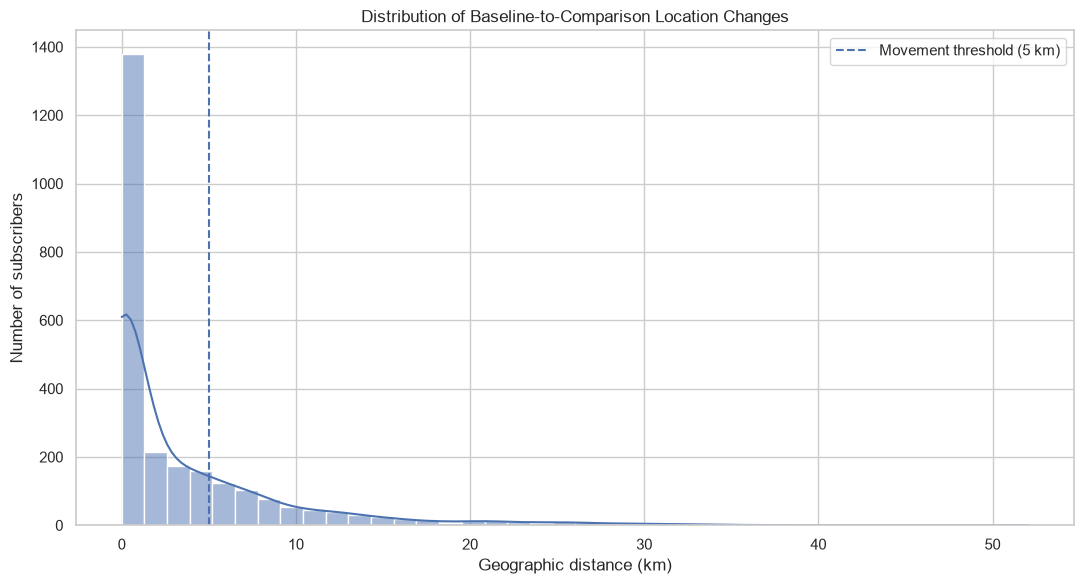

In [179]:
# Visualise the distance distribution

distance_data = movement_analysis[
    "baseline_to_followup_distance_km"
].dropna()


plt.figure(figsize=(11, 6))

sns.histplot(
    distance_data,
    bins=40,
    kde=True
)

plt.axvline(
    MIN_MOVEMENT_DISTANCE_KM,
    linestyle="--",
    label="Movement threshold (5 km)"
)

plt.title(
    "Distribution of Baseline-to-Comparison Location Changes"
)

plt.xlabel("Geographic distance (km)")

plt.ylabel("Number of subscribers")

plt.legend()

plt.tight_layout()

plt.show()

### Interpretation and Summary

The histogram illustrates the distribution of geographic changes between subscribers' baseline and follow-up dominant nighttime locations.

**Key observations:**

- **High concentration near zero:** Most subscribers experienced little or no geographic movement, with the largest concentration occurring around 0–1 km.
- **Right-skewed distribution:** The distribution has a long tail extending beyond 50 km, indicating that substantial movements occurred among a relatively small group.
- **5 km movement threshold:** The dashed vertical line represents the threshold used to identify potentially meaningful geographic changes.
- **Limited large movements:** Subscriber counts decline progressively as geographic distance increases.
- **Potential outliers:** A small number of subscribers experienced location changes exceeding 20 km, with the maximum reaching approximately 52 km.

**Key takeaway:**

The majority of subscribers maintained relatively stable nighttime locations between the two observation periods. However, a smaller population experienced geographic shifts exceeding the 5 km movement threshold.

**Conclusion:** The distribution supports the use of a 5 km threshold as an initial screening criterion for identifying potentially meaningful geographic changes. However, crossing this threshold alone does not establish residential relocation or displacement; observation coverage and persistence must also be considered.

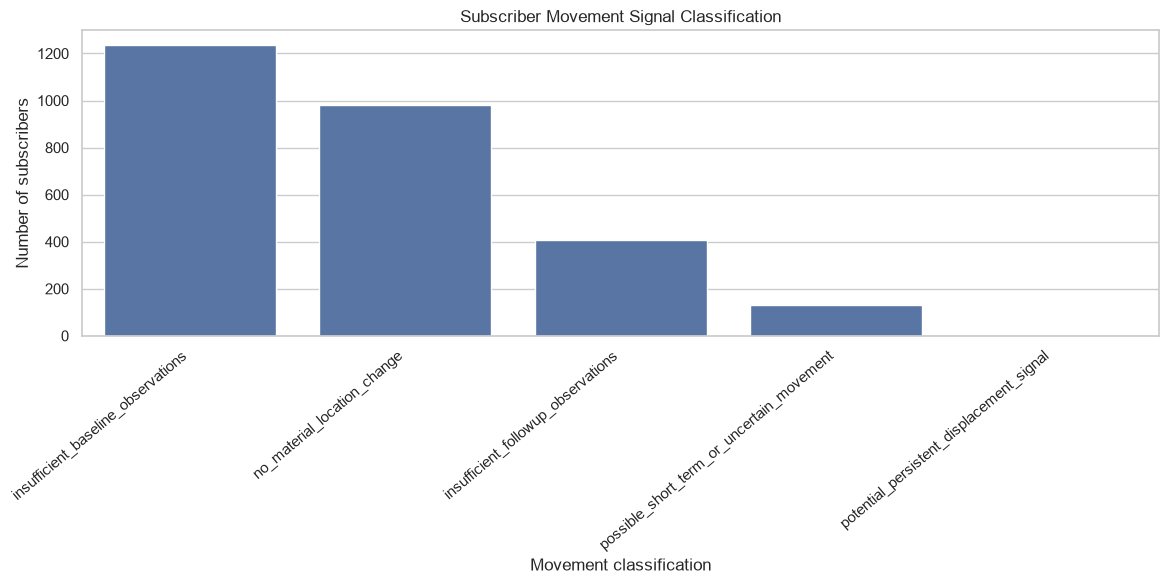

In [180]:
# Compare the number of subscribers across movement categories

plt.figure(figsize=(12, 6))

sns.barplot(
    data=movement_summary,
    x="movement_signal",
    y="subscriber_count"
)

plt.title("Subscriber Movement Signal Classification")

plt.xlabel("Movement classification")

plt.ylabel("Number of subscribers")

plt.xticks(
    rotation=40,
    ha="right"
)

plt.tight_layout()

plt.show()

### Interpretation and Summary

The chart shows how subscribers are distributed across the five movement-signal classifications.

**Key observations:**

- **Insufficient baseline observations:** The largest group, approximately 1,230 subscribers, lacked sufficient baseline data to establish a reliable starting location.
- **No material location change:** Approximately 980 subscribers maintained relatively consistent dominant nighttime locations.
- **Insufficient follow-up observations:** Around 405 subscribers lacked enough follow-up data to reliably assess movement.
- **Possible short-term or uncertain movement:** Approximately 130 subscribers experienced geographic changes that did not satisfy the criteria for persistent movement.
- **Potential persistent displacement:** Only one subscriber was classified as a potential persistent displacement candidate.

**Key takeaway:**

The majority of subscribers either lacked sufficient observation coverage or maintained relatively stable nighttime locations. Only a small proportion demonstrated potentially meaningful but uncertain geographic movement.

**Conclusion:** The analysis suggests relatively high geographic stability among subscribers with sufficient observations. However, limited observation coverage remains a significant constraint on confidently identifying potential displacement.

#### Section 13. Construct origin–destination flows

This analysis aggregates subscriber movements between dominant nighttime cells.

Only include subscribers with sufficient observations in both periods and suppress flows involving fewer than five subscribers.

In [181]:
flow_population = movement_analysis[
    (
        movement_analysis["baseline_observed_nights"]
        >= MIN_BASELINE_NIGHTS
    )
    &
    (
        movement_analysis["followup_observed_nights"]
        >= MIN_FOLLOWUP_NIGHTS
    )
    &
    movement_analysis["baseline_dominant_cell"].notna()
    &
    movement_analysis["followup_dominant_cell"].notna()
].copy()


origin_destination = (
    flow_population.groupby(
        [
            "baseline_dominant_cell",
            "followup_dominant_cell"
        ],
        observed=True
    )
    .agg(
        subscriber_count=("msisdn", "nunique"),
        median_movement_distance_km=(
            "baseline_to_followup_distance_km",
            "median"
        )
    )
    .reset_index()
)


origin_destination = origin_destination.rename(
    columns={
        "baseline_dominant_cell": "origin_cell",
        "followup_dominant_cell": "destination_cell"
    }
)


# Apply minimum group-size suppression.
origin_destination["suppressed"] = (
    origin_destination["subscriber_count"]
    < MIN_FLOW_SUBSCRIBERS
)


origin_destination_public = origin_destination[
    ~origin_destination["suppressed"]
].copy()


display(
    origin_destination_public.sort_values(
        "subscriber_count",
        ascending=False
    ).head(20)
)

,origin_cell,destination_cell,subscriber_count,median_movement_distance_km,suppressed


In [182]:
# Create a pivot table for the origin–destination matrix

od_matrix = origin_destination_public.pivot_table(
    index="origin_cell",
    columns="destination_cell",
    values="subscriber_count",
    aggfunc="sum",
    fill_value=0
)


display(od_matrix.head(20))

destination_cell
origin_cell


### Interpretation and Summary

The origin-destination analysis aims to identify how subscribers move between their baseline and follow-up dominant nighttime cells.

**Key observation:**

The displayed output contains column headers but no data rows. This indicates that `origin_destination_public` is empty, meaning no origin-destination groups survived the filtering and suppression process.

**Possible explanations:**

1. **Insufficient observations:** Subscribers may not meet the minimum baseline and follow-up observation requirements.
2. **Small movement groups:** Origin-destination groups may have fewer subscribers than the `MIN_FLOW_SUBSCRIBERS` threshold.
3. **Missing location information:** Some subscribers may lack valid baseline or follow-up dominant cell IDs.

**Key takeaway:**

No publishable origin-destination flows are currently available. This does not necessarily mean subscribers did not move; the filtering and privacy suppression rules may have excluded the results.


In [183]:
# Check the following to identify where records are being eliminated:

print("Total subscribers:", len(movement_analysis))
print("Eligible subscribers:", len(flow_population))
print("Origin-destination groups:", len(origin_destination))
print("Suppressed groups:", origin_destination["suppressed"].sum())
print("Publishable groups:", len(origin_destination_public))

Total subscribers: 2758
Eligible subscribers: 1115
Origin-destination groups: 1095
Suppressed groups: 1095
Publishable groups: 0


In [184]:
# Investigate why the origin-destination flows returns no data

print("=" * 50)
print("ORIGIN-DESTINATION DIAGNOSTICS")
print("=" * 50)

print("Total subscribers:", movement_analysis["msisdn"].nunique())

print("Eligible subscribers:", flow_population["msisdn"].nunique())

print("Origin-destination groups:", len(origin_destination))

print(
    "Suppressed groups:",
    origin_destination["suppressed"].sum()
)

print("Publishable groups:", len(origin_destination_public))


if not origin_destination.empty:

    print("\nLargest origin-destination groups:")

    display(
        origin_destination.sort_values(
            "subscriber_count",
            ascending=False
        ).head(15)
    )

    print("\nSubscriber count distribution:")

    display(
        origin_destination["subscriber_count"]
        .value_counts()
        .sort_index()
        .rename_axis("subscribers_per_cell_pair")
        .reset_index(name="number_of_pairs")
    )

else:
    print("\nNo origin-destination groups were generated.")

ORIGIN-DESTINATION DIAGNOSTICS
Total subscribers: 2758
Eligible subscribers: 1115
Origin-destination groups: 1095
Suppressed groups: 1095
Publishable groups: 0

Largest origin-destination groups:


,origin_cell,destination_cell,subscriber_count,median_movement_distance_km,suppressed
952,41524,41524,2,0.000,True
260,15151,15151,2,0.000,True
753,28738,28738,2,0.000,True
629,25145,25145,2,0.000,True
757,28813,28813,2,0.000,True
744,28444,28444,2,0.000,True
361,17642,17642,2,0.000,True
735,28182,28182,2,0.000,True
95,11870,11870,2,0.000,True
1044,6408,6408,2,0.000,True



Subscriber count distribution:


,subscribers_per_cell_pair,number_of_pairs
0,1,1075
1,2,20


##### improve the geographic aggregation rather than lower the privacy threshold

In [185]:
# 1 — Separate stayers from movers

flow_population = flow_population.copy()

flow_population["movement_type"] = np.where(
    flow_population["baseline_to_followup_distance_km"]
    >= MIN_MOVEMENT_DISTANCE_KM,
    "geographic_movement",
    "no_material_geographic_change"
)

movement_type_summary = (
    flow_population["movement_type"]
    .value_counts()
    .rename_axis("movement_type")
    .reset_index(name="subscriber_count")
)

movement_type_summary["percentage"] = (
    movement_type_summary["subscriber_count"]
    / movement_type_summary["subscriber_count"].sum()
    * 100
)

display(movement_type_summary)

,movement_type,subscriber_count,percentage
0,no_material_geographic_change,983,88.161
1,geographic_movement,132,11.839


### Interpretation and Summary

The analysis separates subscribers into two groups based on whether their dominant nighttime location changed by at least the defined 5 km movement threshold.

**Key observations:**

- **No material geographic change:** 983 subscribers (88.16%) maintained relatively stable dominant nighttime locations.
- **Geographic movement:** 132 subscribers (11.84%) experienced geographic shifts of at least 5 km between the baseline and follow-up periods.

**Key takeaway:**

The overwhelming majority of subscribers (88.16%) remained geographically stable, while approximately 1 in 8 subscribers (11.84%) experienced potentially meaningful geographic movement.

**Conclusion:** The results indicate relatively high geographic stability across the observed subscriber population, with a smaller group exhibiting location changes that warrant further investigation. These movements should not automatically be interpreted as residential relocation or displacement.

In [186]:
# 2 - FILTER SUBSCRIBERS WITH MEANINGFUL MOVEMENT
# Keep only geographic movers
moving_subscribers = flow_population[
    flow_population["movement_type"]
    == "geographic_movement"
].copy()


print(
    "Subscribers with meaningful geographic movement:",
    moving_subscribers["msisdn"].nunique()
)

print(
    "Median movement distance:",
    moving_subscribers[
        "baseline_to_followup_distance_km"
    ].median()
)

Subscribers with meaningful geographic movement: 132
Median movement distance: 8.748870935140431


In [187]:
# 3 — Create geographic grid aggregation zones
# Use 0.05-degree grid cells. At Kenya's latitude, this is roughly 5.5 km north–south and somewhat less east–west.

GRID_SIZE = 0.05


def create_geo_zone(latitude, longitude, grid_size=GRID_SIZE):

    lat_zone = np.floor(latitude / grid_size).astype("Int64")

    lon_zone = np.floor(longitude / grid_size).astype("Int64")

    return (
        lat_zone.astype(str)
        + "_"
        + lon_zone.astype(str)
    )


moving_subscribers["origin_zone"] = create_geo_zone(
    moving_subscribers["baseline_latitude"],
    moving_subscribers["baseline_longitude"]
)

moving_subscribers["destination_zone"] = create_geo_zone(
    moving_subscribers["followup_latitude"],
    moving_subscribers["followup_longitude"]
)


display(
    moving_subscribers[
        [
            "msisdn",
            "baseline_to_followup_distance_km",
            "origin_zone",
            "destination_zone"
        ]
    ].head(10)
)

,msisdn,baseline_to_followup_distance_km,origin_zone,destination_zone
2,subscribers_00002,11.429,-25_737,-27_737
14,subscribers_00014,6.701,-25_735,-26_736
70,subscribers_00076,11.017,-27_735,-26_737
71,subscribers_00077,11.617,-27_736,-25_735
101,subscribers_00109,10.858,-26_736,-25_737
113,subscribers_00124,52.074,-25_733,-30_740
136,subscribers_00149,5.947,-26_735,-27_736
143,subscribers_00159,10.388,-27_735,-25_735
150,subscribers_00167,10.419,-26_736,-27_737
171,subscribers_00190,14.074,-27_736,-25_735


### Interpretation and Summary

The analysis converts subscribers' baseline and follow-up coordinates into geographic grid zones using a 0.05-degree grid size. This allows movements to be aggregated geographically rather than analysed using individual cell IDs.

**Key observations:**

- **Origin zone:** Represents the geographic grid containing the subscriber's baseline dominant nighttime location.
- **Destination zone:** Represents the grid containing the follow-up dominant nighttime location.
- **Grid resolution:** Each grid cell covers approximately 5.5 km north–south, with a smaller east–west distance.
- **Geographic movement:** The sample shows subscribers moving between different geographic zones, with distances ranging from approximately 5.9 km to 52.1 km.
- **Large movements:** Subscriber `subscribers_000124` recorded the largest movement in this sample, approximately 52.1 km.

**Key takeaway:**

Geographic grid aggregation provides a consistent spatial framework for identifying origin-destination movement patterns. It also reduces reliance on individual network cell IDs, making it easier to identify broader movement corridors and destination hotspots.

**Conclusion:** The resulting origin and destination zones provide the foundation for constructing aggregated geographic movement flows while supporting subscriber privacy.

In [188]:
# 4 — Aggregate geographic origin–destination flows

geographic_flows = (
    moving_subscribers.groupby(
        [
            "origin_zone",
            "destination_zone"
        ],
        observed=True
    )
    .agg(
        subscriber_count=("msisdn", "nunique"),
        median_movement_distance_km=(
            "baseline_to_followup_distance_km",
            "median"
        )
    )
    .reset_index()
)


# Apply privacy suppression.

geographic_flows["suppressed"] = (
    geographic_flows["subscriber_count"]
    < MIN_FLOW_SUBSCRIBERS
)


geographic_flows_public = geographic_flows[
    ~geographic_flows["suppressed"]
].copy()


print("Geographic OD pairs:", len(geographic_flows))

print(
    "Suppressed geographic pairs:",
    geographic_flows["suppressed"].sum()
)

print(
    "Publishable geographic pairs:",
    len(geographic_flows_public)
)


display(
    geographic_flows_public.sort_values(
        "subscriber_count",
        ascending=False
    ).head(20)
)

Geographic OD pairs: 90
Suppressed geographic pairs: 89
Publishable geographic pairs: 1


,origin_zone,destination_zone,subscriber_count,median_movement_distance_km,suppressed
44,-26_736,-27_735,7,6.874,False


### Interpretation and Summary

The geographic origin-destination analysis aggregates subscribers into broader geographic zones to identify recurring movement corridors while applying privacy suppression.

**Key observations:**

- **90 geographic OD pairs:** A total of 90 distinct origin-destination combinations were identified among subscribers exhibiting geographic movement.
- **89 suppressed pairs:** Approximately 98.9% of the OD pairs were suppressed because they did not meet the minimum subscriber threshold.
- **1 publishable pair:** Only one geographic movement corridor satisfied the privacy requirements.
- **Origin zone:** `-26_736`.
- **Destination zone:** `-27_735`.
- **Subscriber count:** 7 subscribers followed this movement corridor.
- **Median movement distance:** 6.874 km.

**Key takeaway:**

Although 90 geographic movement corridors were identified, most had insufficient subscriber counts for safe publication. One corridor emerged as sufficiently populated, with seven subscribers moving between the same geographic zones.

**Conclusion:** Geographic aggregation provides a useful way to identify potential movement corridors while protecting subscriber privacy. However, the high suppression rate indicates that movement patterns are widely dispersed across the study area, limiting the number of corridors that can be publicly reported.

In [189]:
# 5 — Create the geographic origin–destination matrix

od_matrix_geo = geographic_flows_public.pivot_table(
    index="origin_zone",
    columns="destination_zone",
    values="subscriber_count",
    aggfunc="sum",
    fill_value=0
)


display(od_matrix_geo.head(20))

destination_zone,-27_735
origin_zone,
-26_736,7


### Interpretation and Summary

The geographic origin-destination matrix represents the number of subscribers moving between different geographic zones.

**Key observations:**

- **Origin zone:** `-26_736` represents the starting geographic area.
- **Destination zone:** `-27_735` represents the follow-up geographic area.
- **Subscriber count:** 7 subscribers made this transition.
- **Matrix structure:** Rows represent origin zones, columns represent destination zones, and cell values represent subscriber counts.
- **Privacy protection:** Only the publishable geographic movement corridor is included in the matrix.

**Key takeaway:**

The matrix confirms one publishable movement corridor, with seven subscribers moving from zone `-26_736` to zone `-27_735`.

**Conclusion:** The origin-destination matrix provides a simplified representation of aggregate subscriber movement and can serve as an input for geographic flow visualisation and spatial mobility analysis.

In [190]:
# Test aggregation sensitivity(GRID SIZE SENSITIVITY ANALYSIS)
# Do not assume 5 km is the ideal geographic scale. 
# Test multiple grid sizes and compare the number of groups surviving suppression.

grid_results = []

for grid_size in [0.02, 0.05, 0.10, 0.15]:

    temp = moving_subscribers.copy()

    temp["origin_zone"] = create_geo_zone(
        temp["baseline_latitude"],
        temp["baseline_longitude"],
        grid_size
    )

    temp["destination_zone"] = create_geo_zone(
        temp["followup_latitude"],
        temp["followup_longitude"],
        grid_size
    )

    flows = (
        temp.groupby(
            ["origin_zone", "destination_zone"],
            observed=True
        )
        .agg(
            subscriber_count=("msisdn", "nunique")
        )
        .reset_index()
    )

    grid_results.append({
        "grid_size_degrees": grid_size,
        "approx_latitude_cell_km": grid_size * 111,
        "total_geographic_flows": len(flows),
        "publishable_flows": (
            flows["subscriber_count"] >= MIN_FLOW_SUBSCRIBERS
        ).sum(),
        "suppressed_flows": (
            flows["subscriber_count"] < MIN_FLOW_SUBSCRIBERS
        ).sum()
    })


grid_sensitivity = pd.DataFrame(grid_results)

display(grid_sensitivity)

,grid_size_degrees,approx_latitude_cell_km,total_geographic_flows,publishable_flows,suppressed_flows
0,0.020,2.220,129,0,129
1,0.050,5.550,90,1,89
2,0.100,11.100,44,7,37
3,0.150,16.650,18,3,15


### Origin–Destination Analysis: Interpretation

The initial cell-level origin–destination analysis identified 1,095
unique origin–destination pairs across 1,115 eligible subscribers.

However, all 1,095 pairs were suppressed because no pair contained
more than two subscribers. This demonstrates that exact cell-level
aggregation produced highly fragmented movement groups.

The initial results therefore did not provide publishable
origin–destination flows.

To address this, the analysis was extended to geographic grid
aggregation, allowing subscribers moving between nearby cells to
be grouped into broader geographic origin and destination zones.

A minimum group-size threshold of five subscribers was retained
to avoid weakening the privacy protection requirement.

Grid-size sensitivity analysis was introduced to evaluate the
trade-off between geographic resolution and the number of
publishable movement flows.

Importantly, these results represent changes in dominant nighttime
locations and should not be interpreted as confirmed displacement.

#### Section 14. Identify destination hotspots

Identify destination cells receiving the highest number of subscribers whose dominant nighttime location changed by at least 5 km.

In [191]:
# Rebuild the destination hotspot table before suppression
# DESTINATION HOTSPOTS - BEFORE PRIVACY SUPPRESSION

destination_hotspots_raw = (
    potential_movement_population.groupby(
        "followup_dominant_cell",
        observed=True
    )
    .agg(
        subscriber_count=("msisdn", "nunique"),
        median_inbound_distance_km=(
            "baseline_to_followup_distance_km",
            "median"
        )
    )
    .reset_index()
    .rename(
        columns={
            "followup_dominant_cell": "destination_cell"
        }
    )
)


# Add geographic coordinates.
destination_hotspots_raw = destination_hotspots_raw.merge(
    cell_lookup,
    left_on="destination_cell",
    right_on="cell_id",
    how="left",
    validate="many_to_one"
)


destination_hotspots_raw = destination_hotspots_raw.drop(
    columns=["cell_id"],
    errors="ignore"
)


# Inspect the actual distribution.
print("Total destination cells:", len(destination_hotspots_raw))

print(
    "Maximum subscribers per destination cell:",
    destination_hotspots_raw["subscriber_count"].max()
)

print("\nDestination subscriber distribution:")

display(
    destination_hotspots_raw["subscriber_count"]
    .value_counts()
    .sort_index()
    .rename_axis("subscribers_per_destination")
    .reset_index(name="number_of_destination_cells")
)


print("\nLargest destination cells before suppression:")

display(
    destination_hotspots_raw.sort_values(
        "subscriber_count",
        ascending=False
    ).head(20)
)

Total destination cells: 211
Maximum subscribers per destination cell: 2

Destination subscriber distribution:


,subscribers_per_destination,number_of_destination_cells
0,1,209
1,2,2



Largest destination cells before suppression:


,destination_cell,subscriber_count,median_inbound_distance_km,cell_latitude,cell_longitude,coordinate_observations
53,12520,2,11.810,-1.223,36.805,10
27,10805,2,6.822,-1.294,36.789,9
135,21974,1,8.695,-1.315,36.855,37
136,21978,1,9.952,-1.294,36.855,16
137,22069,1,9.840,-1.330,36.856,12
138,22094,1,7.329,-1.311,36.856,8
139,22098,1,20.711,-1.261,36.856,22
140,22205,1,5.338,-1.310,36.857,4
141,22910,1,12.200,-1.254,36.862,29
142,22921,1,22.916,-1.284,36.862,88


### Interpretation and Summary

The analysis examines how subscribers are distributed across destination cells following geographic movement, before applying privacy suppression.

**Key observations:**

- **Total destination cells:** 211 distinct destination cells were identified.
- **Low destination concentration:** 209 cells (99.1%) received only one subscriber each.
- **Maximum concentration:** Only two destination cells received two subscribers each.
- **Largest destination cell:** Cell `12520` and cell `10805` each attracted two subscribers.
- **Geographic dispersion:** Destination cells are spread across different coordinates, suggesting that subscribers' movements are geographically dispersed rather than concentrated around a few common destinations.
- **Inbound movement distance:** The median inbound distance for the two largest destination cells was 11.81 km and 6.82 km, respectively.

**Key takeaway:**

There is no significant concentration of subscribers around individual destination cells. Almost every destination cell is associated with just one subscriber, indicating highly dispersed movement patterns.

**Conclusion:** Destination-level hotspot analysis reveals limited geographic clustering. Individual cell-level aggregation is unlikely to produce meaningful publishable hotspots under the current privacy threshold. Broader geographic aggregation, such as the 0.05-degree grid zones, may provide more useful insights while preserving subscriber confidentiality.

In [192]:
# Aggregate destinations into geographic zones
# GEOGRAPHIC DESTINATION HOTSPOTS

GRID_SIZE = 0.05

destination_data = potential_movement_population.copy()


destination_data["destination_lat_zone"] = (
    np.floor(
        destination_data["followup_latitude"] / GRID_SIZE
    ) * GRID_SIZE
)

destination_data["destination_lon_zone"] = (
    np.floor(
        destination_data["followup_longitude"] / GRID_SIZE
    ) * GRID_SIZE
)


destination_data["destination_zone"] = (
    destination_data["destination_lat_zone"].round(3).astype(str)
    + "_"
    + destination_data["destination_lon_zone"].round(3).astype(str)
)


# Aggregate subscribers by destination zone.
destination_hotspots_geo = (
    destination_data.groupby(
        [
            "destination_zone",
            "destination_lat_zone",
            "destination_lon_zone"
        ],
        observed=True
    )
    .agg(
        subscriber_count=("msisdn", "nunique"),
        median_inbound_distance_km=(
            "baseline_to_followup_distance_km",
            "median"
        )
    )
    .reset_index()
)


# Apply privacy suppression.
destination_hotspots_geo["suppressed"] = (
    destination_hotspots_geo["subscriber_count"]
    < MIN_FLOW_SUBSCRIBERS
)


destination_hotspots_geo_public = (
    destination_hotspots_geo[
        ~destination_hotspots_geo["suppressed"]
    ]
    .sort_values(
        "subscriber_count",
        ascending=False
    )
)


print("Geographic destination zones:",
      len(destination_hotspots_geo))

print("Suppressed zones:",
      destination_hotspots_geo["suppressed"].sum())

print("Publishable zones:",
      len(destination_hotspots_geo_public))


display(destination_hotspots_geo_public.head(20))

Geographic destination zones: 30
Suppressed zones: 21
Publishable zones: 9


,destination_zone,destination_lat_zone,destination_lon_zone,subscriber_count,median_inbound_distance_km,suppressed
19,-1.3_36.8,-1.300,36.800,43,7.180,False
14,-1.35_36.8,-1.350,36.800,22,8.383,False
20,-1.3_36.85,-1.300,36.850,19,10.817,False
18,-1.3_36.75,-1.300,36.750,18,8.196,False
13,-1.35_36.75,-1.350,36.750,17,8.372,False
15,-1.35_36.85,-1.350,36.850,17,8.695,False
6,-1.25_36.85,-1.250,36.850,15,9.663,False
5,-1.25_36.8,-1.250,36.800,12,9.546,False
4,-1.25_36.75,-1.250,36.750,8,11.507,False


### Interpretation and Summary

The analysis aggregates subscriber destinations into larger geographic zones using a 0.05-degree grid, allowing movement hotspots to be identified more effectively than individual cell-level analysis.

**Key observations:**

- **Total geographic destination zones:** 30.
- **Suppressed zones:** 21 (70%), because they did not meet the minimum subscriber threshold.
- **Publishable zones:** 9 (30%), providing sufficient subscriber counts for reporting.
- **Largest destination hotspot:** Zone `-1.3_36.8`, attracting **43 subscribers**, with a median inbound movement distance of 7.18 km.
- **Second-largest hotspot:** Zone `-1.35_36.8`, attracting **22 subscribers**, with a median inbound distance of 8.38 km.
- **Other hotspots:** The remaining publishable zones attracted between 8 and 19 subscribers each.
- **Movement distances:** Median inbound distances across the nine zones range from approximately 7.18 km to 11.51 km.

**Key takeaway:**

Geographic aggregation significantly improves destination hotspot identification. Unlike individual cell-level analysis, which showed almost no subscriber concentration, the larger geographic zones reveal identifiable destination clusters.

**Conclusion:** Nine destination zones meet the privacy threshold, with zone `-1.3_36.8` emerging as the strongest destination hotspot. This suggests that geographic grid aggregation provides a more meaningful way to identify potential population movement patterns while protecting subscriber privacy.

In [193]:
# Test different geographic resolutions
# DESTINATION GRID SENSITIVITY

grid_results = []

for grid_size in [0.02, 0.05, 0.10, 0.15, 0.20]:

    temp = potential_movement_population.copy()

    temp["lat_zone"] = (
        np.floor(
            temp["followup_latitude"] / grid_size
        ) * grid_size
    )

    temp["lon_zone"] = (
        np.floor(
            temp["followup_longitude"] / grid_size
        ) * grid_size
    )

    grouped = (
        temp.groupby(
            ["lat_zone", "lon_zone"],
            observed=True
        )
        .agg(
            subscriber_count=("msisdn", "nunique")
        )
        .reset_index()
    )

    grid_results.append({
        "grid_size_degrees": grid_size,
        "approx_north_south_km": grid_size * 111,
        "destination_zones": len(grouped),
        "publishable_zones": (
            grouped["subscriber_count"] >= MIN_FLOW_SUBSCRIBERS
        ).sum(),
        "suppressed_zones": (
            grouped["subscriber_count"] < MIN_FLOW_SUBSCRIBERS
        ).sum()
    })


grid_sensitivity = pd.DataFrame(grid_results)

display(grid_sensitivity)

,grid_size_degrees,approx_north_south_km,destination_zones,publishable_zones,suppressed_zones
0,0.020,2.220,77,16,61
1,0.050,5.550,30,9,21
2,0.100,11.100,15,8,7
3,0.150,16.650,8,7,1
4,0.200,22.200,9,4,5


### Interpretation and Summary

The sensitivity analysis evaluates how changing the geographic grid size affects destination hotspot identification and privacy suppression.

**Key observations:**

- **0.02° grid (~2.22 km):** Produces 77 destination zones, but only 16 are publishable. Most zones (61) are suppressed due to low subscriber counts.
- **0.05° grid (~5.55 km):** Produces 30 zones, with 9 publishable and 21 suppressed.
- **0.10° grid (~11.1 km):** Produces 15 zones, of which 8 are publishable. This provides a better balance between geographic detail and subscriber aggregation.
- **0.15° grid (~16.65 km):** Produces 8 zones, with 7 publishable and only 1 suppressed.
- **0.20° grid (~22.2 km):** Produces 9 zones, but only 4 are publishable, indicating that larger grids do not necessarily improve publishability.

**Key takeaway:**

Smaller grid sizes preserve geographic precision but result in more privacy suppression. Larger grids aggregate subscribers into broader geographic areas, improving publishability but reducing spatial resolution.

**Conclusion:** The 0.05° grid offers a reasonable balance between geographic precision and privacy. However, the 0.10° grid is also worth considering because it produces 8 publishable zones out of 15, compared with 9 out of 30 at 0.05°. The final choice should depend on whether geographic detail or broader destination hotspot identification is the primary objective.

#### Section 15. Analyse baseline and comparison coverage

Before interpreting movement, check whether subscribers have enough observations in both periods. A missing observation should not be interpreted as a departure.

In [194]:
total_ordinary_subscribers = len(ordinary_ids)

coverage_summary = pd.DataFrame({
    "metric": [
        "Ordinary subscribers",
        "Subscribers observed during baseline",
        "Subscribers observed during comparison",
        "Subscribers observed in both periods",
        "Subscribers with sufficient baseline observations",
        "Subscribers with sufficient comparison observations",
        "Subscribers with sufficient observations in both periods"
    ],
    "value": [
        total_ordinary_subscribers,
        baseline_location["msisdn"].nunique(),
        followup_location["msisdn"].nunique(),
        movement_analysis.dropna(
            subset=[
                "baseline_observed_nights",
                "followup_observed_nights"
            ]
        )["msisdn"].nunique(),
        (
            movement_analysis["baseline_observed_nights"]
            >= MIN_BASELINE_NIGHTS
        ).sum(),
        (
            movement_analysis["followup_observed_nights"]
            >= MIN_FOLLOWUP_NIGHTS
        ).sum(),
        movement_analysis["sufficient_period_evidence"].sum()
    ]
})

coverage_summary["percentage_of_ordinary_subscribers"] = (
    coverage_summary["value"]
    / total_ordinary_subscribers
    * 100
)


display(coverage_summary)

,metric,value,percentage_of_ordinary_subscribers
0,Ordinary subscribers,2813,100.000
1,Subscribers observed during baseline,2642,93.921
2,Subscribers observed during comparison,2654,94.348
3,Subscribers observed in both periods,2538,90.224
4,Subscribers with sufficient baseline observations,1428,50.764
5,Subscribers with sufficient comparison observa...,1372,48.774
6,Subscribers with sufficient observations in bo...,1115,39.637


### Interpretation and Summary

The coverage analysis shows that the dataset contains **2,813 ordinary subscribers**, with relatively strong representation across both observation periods.

**Key observations:**

- **Baseline coverage:** 2,642 subscribers (93.92%) were observed during the baseline period.
- **Comparison coverage:** 2,654 subscribers (94.35%) were observed during the comparison period.
- **Both periods:** 2,538 subscribers (90.22%) had observations in both periods.
- **Sufficient baseline observations:** 1,428 subscribers (50.76%) met the minimum baseline observation requirements.
- **Sufficient comparison observations:** 1,372 subscribers (48.77%) met the minimum comparison observation requirements.
- **Sufficient observations in both periods:** Only 1,115 subscribers (39.64%) met the minimum observation requirements across both periods.

**Key takeaway:**

Although overall subscriber coverage is high (over 90% in both periods), the number of subscribers with sufficient observations for reliable movement analysis drops to 1,115 (39.64%).

**Conclusion:** The analysis has good overall subscriber coverage, but observation sufficiency is a significant constraint. Movement estimates should therefore be based on the 1,115 subscribers with adequate observations in both periods, rather than the entire subscriber population.

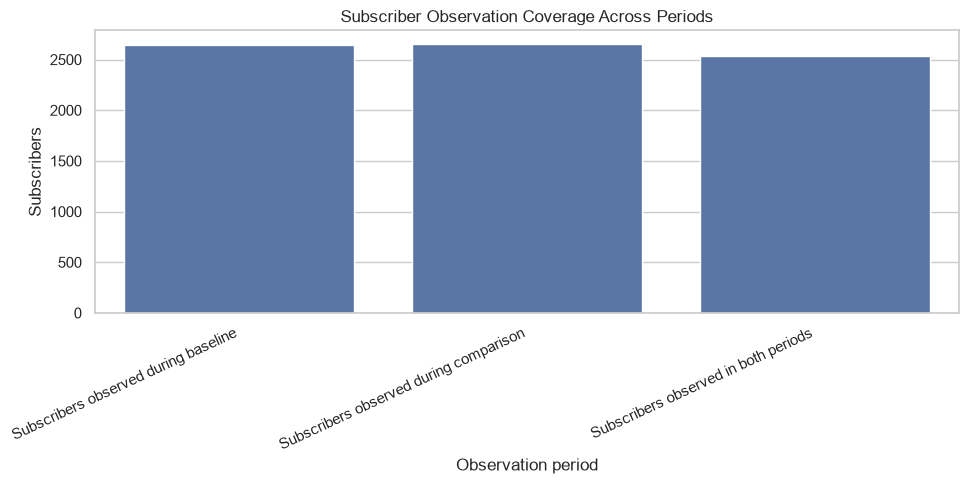

In [195]:
# Visualise observation coverage

coverage_plot = coverage_summary.iloc[1:4].copy()

plt.figure(figsize=(10, 5))

sns.barplot(
    data=coverage_plot,
    x="metric",
    y="value"
)

plt.title("Subscriber Observation Coverage Across Periods")

plt.xlabel("Observation period")

plt.ylabel("Subscribers")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The chart shows relatively consistent subscriber observation coverage across the baseline and comparison periods.

**Key observations:**

- **Baseline:** 2,642 subscribers were observed.
- **Comparison:** 2,654 subscribers were observed, slightly higher than the baseline.
- **Both periods:** 2,538 subscribers had observations in both periods.

**Key takeaway:**

Subscriber coverage is relatively balanced across both periods, with approximately 90% of ordinary subscribers observed in both. The small difference between baseline and comparison coverage suggests that neither period has a substantial advantage in overall subscriber representation.

**Conclusion:** The dataset provides a reasonably consistent subscriber population for comparing geographic patterns across the two periods. However, having observations in both periods does not necessarily mean subscribers have sufficient observations to support reliable movement classification.

#### Section 16. Examine potential displacement candidates

In [196]:
displacement_candidates = movement_analysis[
    movement_analysis["potential_displacement_candidate"]
].copy()


candidate_columns = [
    "msisdn",
    "residence_classification",
    "residence_evidence_level",
    "baseline_dominant_cell",
    "followup_dominant_cell",
    "baseline_observed_nights",
    "followup_observed_nights",
    "baseline_dominance",
    "followup_dominance",
    "followup_dominant_active_weeks",
    "baseline_to_followup_distance_km",
    "movement_signal"
]


display(
    displacement_candidates[
        candidate_columns
    ].sort_values(
        "baseline_to_followup_distance_km",
        ascending=False
    ).head(30)
)


print(
    "Potential persistent displacement signals:",
    len(displacement_candidates)
)

,msisdn,residence_classification,residence_evidence_level,baseline_dominant_cell,followup_dominant_cell,baseline_observed_nights,followup_observed_nights,baseline_dominance,followup_dominance,followup_dominant_active_weeks,baseline_to_followup_distance_km,movement_signal
2,subscribers_00002,recurring_presence_not_yet_stable,moderate,28284,22951,6.000,10.000,0.500,0.700,2.000,11.429,potential_persistent_displacement_signal


Potential persistent displacement signals: 1


### Interpretation and Summary

The analysis identified **1 subscriber** with a potential persistent displacement signal.

**Key observations:**

- **Baseline location:** Cell 28284.
- **Follow-up location:** Cell 22951.
- **Geographic displacement:** 11.429 km, exceeding the 5 km movement threshold.
- **Baseline observations:** 6 nights, with 50% location dominance.
- **Follow-up observations:** 10 nights, with 70% location dominance.
- **Follow-up persistence:** The new dominant location was observed across 2 active weeks.
- **Residence classification:** `recurring_presence_not_yet_stable`.
- **Movement classification:** `potential_persistent_displacement_signal`.

**Key takeaway:**

The subscriber demonstrates a geographically meaningful shift of approximately 11.4 km, with repeated nighttime activity at the new location. However, the baseline residence evidence is only moderate, meaning the original location was not sufficiently established as a stable residence.

**Conclusion:** This subscriber is flagged as a potential displacement candidate, but the result should not be interpreted as confirmed displacement. Further observation and stronger baseline residence evidence would be required to establish whether this represents a genuine residential relocation.

#### Section 17. Export Notebook 04 outputs

In [197]:
# SUBSCRIBER-LEVEL MOVEMENT ANALYSIS
# EXPORT NOTEBOOK 04 OUTPUTS

# 1. Subscriber-level movement analysis
# Keep private. Do not publish to GitHub.
movement_analysis.to_csv(
    NOTEBOOK04_OUTPUT / "potential_displacement_signals.csv",
    index=False
)

# 2. Movement classification summary
movement_summary.to_csv(
    NOTEBOOK04_OUTPUT / "movement_classification_summary.csv",
    index=False
)

# 3. Observation coverage
coverage_summary.to_csv(
    NOTEBOOK04_OUTPUT / "movement_observation_coverage.csv",
    index=False
)

# 4. Geographic origin-destination flows
geographic_flows_public.to_csv(
    NOTEBOOK04_OUTPUT / "mobility_flows_aggregated.csv",
    index=False
)

# 5. Geographic origin-destination matrix
od_matrix_geo.to_csv(
    NOTEBOOK04_OUTPUT / "origin_destination_matrix.csv"
)

# 6. Geographic destination hotspots
destination_hotspots_geo_public.to_csv(
    NOTEBOOK04_OUTPUT / "destination_hotspots_aggregated.csv",
    index=False
)

# 7. Baseline and follow-up period summary
period_summary.to_csv(
    NOTEBOOK04_OUTPUT / "baseline_followup_period_summary.csv",
    index=False
)

# 8. Grid-size sensitivity
grid_sensitivity.to_csv(
    NOTEBOOK04_OUTPUT / "destination_grid_sensitivity.csv",
    index=False
)

print("Notebook 04 exports completed.")

for file in sorted(NOTEBOOK04_OUTPUT.glob("*.csv")):
    print(file.name, f"{file.stat().st_size:,} bytes")

Notebook 04 exports completed.
baseline_followup_period_summary.csv 159 bytes
destination_grid_sensitivity.csv 219 bytes
destination_hotspots_aggregated.csv 600 bytes
mobility_flows_aggregated.csv 126 bytes
movement_analysis_classification.csv 680,215 bytes
movement_classification_summary.csv 337 bytes
movement_observation_coverage.csv 490 bytes
origin_destination_matrix.csv 30 bytes
potential_displacement_signals.csv 680,215 bytes


#### Section 18. Final quality checks

In [198]:
# Ensure one record per subscriber in movement analysis.
assert movement_analysis["msisdn"].is_unique


# Ensure the flow output contains no subscriber identifiers.
assert "msisdn" not in origin_destination_public.columns


# Ensure suppressed flows are not included.
assert (
    origin_destination_public["subscriber_count"]
    >= MIN_FLOW_SUBSCRIBERS
).all()


# Ensure displacement candidates satisfy the minimum criteria.
assert (
    displacement_candidates["baseline_observed_nights"]
    >= MIN_BASELINE_NIGHTS
).all()

assert (
    displacement_candidates["followup_observed_nights"]
    >= MIN_FOLLOWUP_NIGHTS
).all()

assert (
    displacement_candidates["baseline_to_followup_distance_km"]
    >= MIN_MOVEMENT_DISTANCE_KM
).all()


print("All Notebook 04 quality checks passed.")

All Notebook 04 quality checks passed.


#### Notebook 04 — Overall Findings and Conclusion

#### 1. Observation Coverage

The analysis identified 2,813 ordinary subscribers. Although 2,538 subscribers (90.2%) had observations in both periods, only 1,115 (39.6%) met the minimum observation requirements for movement analysis.

This highlights the importance of distinguishing data availability from sufficient evidence for reliable inference.

#### 2. Potential Location Changes

A total of 213 subscribers exhibited geographic changes of at least 5 km between their baseline and follow-up dominant nighttime locations.

However, only one subscriber met all the initial criteria for a potential persistent displacement signal. This result should be treated as exploratory, not as a confirmed displacement case.

#### 3. Origin–Destination Analysis

Exact cell-level aggregation produced highly fragmented flows, with all 1,095 origin–destination pairs failing the minimum five-subscriber reporting threshold.

Geographic aggregation improved the usefulness of the analysis. At a 0.05-degree grid resolution, one origin–destination corridor met the minimum reporting threshold, containing seven subscribers.

#### 4. Destination Hotspots

At a 0.05-degree grid resolution, 30 destination zones were identified. Nine met the minimum five-subscriber threshold.

The largest zone contained 43 subscribers, with a median inbound movement distance of approximately 7.18 km.

#### 5. Methodological Implications

The findings demonstrate that:
- Observation coverage is not equivalent to sufficient evidence.
- Changes in dominant nighttime locations require persistence and baseline stability checks.
- Exact cell-level aggregation can produce fragmented movement patterns.
- Geographic aggregation can improve analytical usefulness, but reduces spatial resolution.
- Privacy suppression can materially affect the availability of publishable results.
- A change in nighttime location does not establish forced displacement.

#### 6. Limitations

The analysis uses synthetic mobile network data covering 28 days. The two observation periods do not establish a verified displacement event.

The selected distance, observation and persistence thresholds are exploratory and require sensitivity testing.

The results cannot establish actual population displacement, long-term residential relocation or the reasons behind observed movement.

#### Conclusion

Notebook 04 establishes an exploratory framework for detecting persistent changes in dominant nighttime locations using mobile network data.

It combines temporal comparison, spatial distance calculations, evidence thresholds, movement classification, origin–destination analysis, destination hotspot detection and privacy-conscious aggregation.

The methodology provides a foundation for further validation and operational refinement in Notebook 05.